In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


In [2]:
file ='/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/final_datasets/a10_lowCF_scaled_filtered_merged_with_incdec.parquet'
df = pd.read_parquet(file, engine='pyarrow')

In [3]:
df

,grid_lat,grid_lon,h_precip_mm,datetime,no2_mean,no2_std,no2_sem,snow_ice_fraction_mean,snow_ice_fraction_std,cv_no2,...,pct_sandy_clay,pct_sandy_clay_loam,pct_sandy_loam,pct_silt,pct_silt_loam,pct_silty_clay,pct_silty_clay_loam,state_name,pre_slope,sm_class
0,36.05,-91.15,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.000000,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,NaN,None
1,36.05,-91.15,NaN,2024-02-29 23:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.000000,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,NaN,None
2,36.05,-91.15,NaN,2024-03-01 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.000000,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,NaN,None
3,36.05,-91.15,NaN,2024-03-01 01:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.000000,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,NaN,None
4,36.05,-91.15,NaN,2024-03-01 02:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.000000,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,NaN,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
33395116,48.95,-96.85,0.345,2024-07-31 19:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,1.515152,88.636364,0.0,0.000000,0.000000,0.000000,Minnesota,NaN,None
33395117,48.95,-96.85,0.050,2024-07-31 20:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,1.515152,88.636364,0.0,0.000000,0.000000,0.000000,Minnesota,NaN,None
33395118,48.95,-96.85,0.000,2024-07-31 21:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,1.515152,88.636364,0.0,0.000000,0.000000,0.000000,Minnesota,NaN,None
33395119,48.95,-96.85,0.000,2024-07-31 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,1.515152,88.636364,0.0,0.000000,0.000000,0.000000,Minnesota,NaN,None


In [4]:
df.columns

Index(['grid_lat', 'grid_lon', 'h_precip_mm', 'datetime', 'no2_mean',
       'no2_std', 'no2_sem', 'snow_ice_fraction_mean', 'snow_ice_fraction_std',
       'cv_no2', 'datetime_local', 'local_hour', 'no2_scaled_by_hour',
       'pulse_start', 'sm_surface', 'surface_temp', 'soil_temp_layer1',
       'WFPS_c', 'dominant_texture', 'pct_clay', 'pct_clay_loam', 'pct_loam',
       'pct_loamy_sand', 'pct_sand', 'pct_sandy_clay', 'pct_sandy_clay_loam',
       'pct_sandy_loam', 'pct_silt', 'pct_silt_loam', 'pct_silty_clay',
       'pct_silty_clay_loam', 'state_name', 'pre_slope', 'sm_class'],
      dtype='object')

In [10]:
# soil moisture stats by dominant texture
texture_sm_stats = (df.groupby("dominant_texture", dropna=False).agg(
    n_rows=("WFPS_c", "size"),
    n_valid_sm=("WFPS_c", "count"),
    mean_sm=("WFPS_c", "mean"),
    median_sm=("WFPS_c", "median"),
    std_sm=("WFPS_c", "std"),
    min_sm=("WFPS_c", "min"),
    max_sm=("WFPS_c", "max")).reset_index())

# optional: percent of rows with valid SMAP soil moisture
texture_sm_stats["pct_valid_sm"] = (texture_sm_stats["n_valid_sm"] / texture_sm_stats["n_rows"] *100)

texture_sm_stats = texture_sm_stats.sort_values("mean_sm", ascending=False)

texture_sm_stats

,dominant_texture,n_rows,n_valid_sm,mean_sm,median_sm,std_sm,min_sm,max_sm,pct_valid_sm
5,sandy clay loam,3674,3672,0.657841,0.681166,0.088113,0.421560,0.859048,99.945563
1,clay loam,2933849,2932253,0.623803,0.647707,0.158614,0.037588,0.982383,99.945600
0,clay,132387,132315,0.617207,0.602888,0.133475,0.151839,0.976478,99.945614
8,silty clay,525977,525691,0.601837,0.596766,0.116644,0.094358,0.954585,99.945625
9,silty clay loam,6737445,6733781,0.601710,0.602669,0.136507,0.054522,0.987637,99.945617
7,silt loam,11122335,11116287,0.574289,0.584066,0.141921,0.020650,0.985530,99.945623
2,loam,9739716,9734420,0.512080,0.498431,0.131930,0.030639,0.971764,99.945625
6,sandy loam,1794903,1790250,0.438493,0.428035,0.157064,0.025887,0.974986,99.740766
3,loamy sand,312765,312595,0.380158,0.370755,0.133742,0.045448,0.969165,99.945646
4,sand,92070,92020,0.319035,0.304186,0.130172,0.049205,0.923522,99.945693


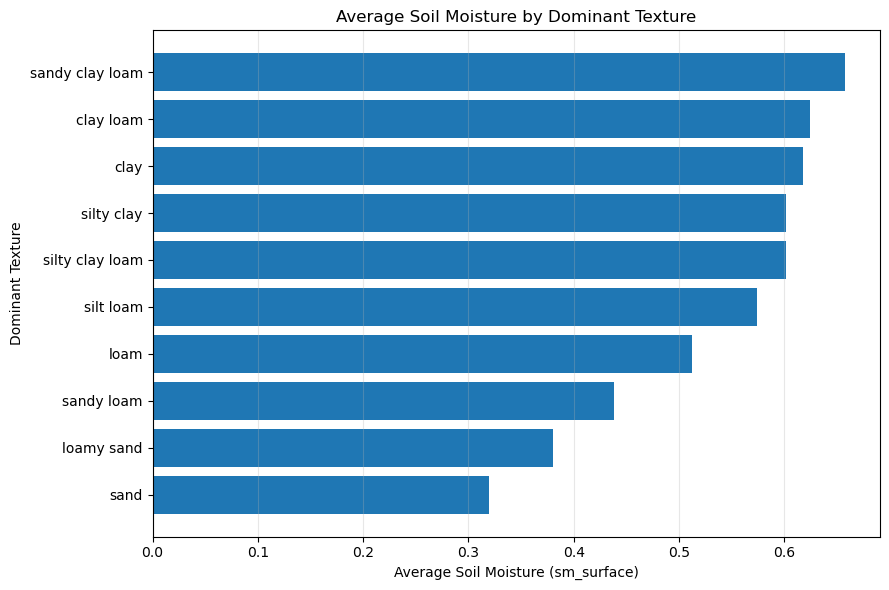

In [11]:
# drop missing texture names if needed
plot_df = texture_sm_stats.dropna(subset=["dominant_texture"]).copy()

# sort so the plot is easier to read
plot_df = plot_df.sort_values("mean_sm", ascending=True)

plt.figure(figsize=(9, 6))

plt.barh(
    plot_df["dominant_texture"],
    plot_df["mean_sm"]
)

plt.xlabel("Average Soil Moisture (sm_surface)")
plt.ylabel("Dominant Texture")
plt.title("Average Soil Moisture by Dominant Texture")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

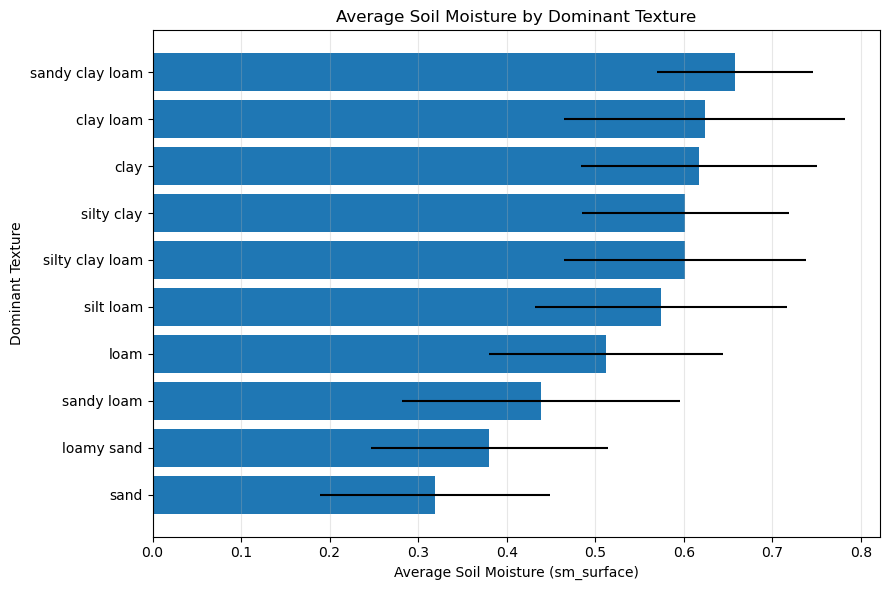

In [12]:
import matplotlib.pyplot as plt

plot_df = texture_sm_stats.dropna(subset=["dominant_texture"]).copy()
plot_df = plot_df.sort_values("mean_sm", ascending=True)

plt.figure(figsize=(9, 6))

plt.barh(
    plot_df["dominant_texture"],
    plot_df["mean_sm"],
    xerr=plot_df["std_sm"]
)

plt.xlabel("Average Soil Moisture (sm_surface)")
plt.ylabel("Dominant Texture")
plt.title("Average Soil Moisture by Dominant Texture")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()